# Лабораторная работа №9

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneOut, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, LabelEncoder
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('../ML-Dataset_cleaned.csv')
feature_columns = ['Profit_Std', 'CreditLimit_Norm', 'Job_Code', 'Profit_Per_Unit']
target_column = 'CategoryName'
df_clean = df[feature_columns + [target_column]].dropna()

le = LabelEncoder()
y = le.fit_transform(df_clean[target_column])
X = df_clean[feature_columns].values

print(f"\nРаспределение классов:")
for i, cls in enumerate(le.classes_):
    print(f"  {cls}: {sum(y == i)} объектов")


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nОбучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка: {X_test.shape[0]} объектов")



def print_classification_report(y_true, y_pred, model_name, classes):
    acc = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f"\n{model_name}")
    print("-" * 50)
    print(f"  Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
    print(f"  Recall:    {recall:.4f} ({recall*100:.2f}%)")
    print(f"  F1-score:  {f1:.4f} ({f1*100:.2f}%)")
    return acc, recall, f1


def find_best_k_loo(X, y, metric, max_k=30, weights='uniform', p=3):
    """Подбор оптимального k методом Leave-One-Out"""
    loo = LeaveOneOut()
    k_values = range(1, max_k + 1)
    accuracies = []

    for k in k_values:
        if metric == 'minkowski':
            knn = KNeighborsClassifier(n_neighbors=k, metric=metric, p=p, weights=weights)
        else:
            knn = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights)

        correct = 0
        total = 0

        for train_idx, test_idx in loo.split(X):
            X_train_loo, X_test_loo = X[train_idx], X[test_idx]
            y_train_loo, y_test_loo = y[train_idx], y[test_idx]

            knn.fit(X_train_loo, y_train_loo)
            y_pred = knn.predict(X_test_loo)

            if y_pred == y_test_loo:
                correct += 1
            total += 1

        accuracies.append(correct / total)

    best_k = k_values[np.argmax(accuracies)]
    best_acc = max(accuracies)
    return best_k, best_acc, k_values, accuracies


# Определяем метрики
metrics = {
    'Евклидова': 'euclidean',
    'Манхэттенская': 'manhattan',
    'Чебышева': 'chebyshev',
    'Минковского (p=3)': 'minkowski'
}

colors = ['blue', 'green', 'red', 'orange', 'purple']


Распределение классов:
  CPU: 90 объектов
  Mother Board: 79 объектов
  RAM: 34 объектов
  Storage: 127 объектов
  Video Card: 70 объектов

Обучающая выборка: 320 объектов
Тестовая выборка: 80 объектов


Реализация метода k ближайших соседей (kNN) с равномерными весами


--------------------------------------------------
1.1 k-NN с равномерными весами (weights='uniform')
--------------------------------------------------

Подбор оптимального k методом LOO
  Евклидова: оптимальное k = 1, точность LOO = 0.7281 (72.81%)
  Манхэттенская: оптимальное k = 3, точность LOO = 0.7250 (72.50%)
  Чебышева: оптимальное k = 1, точность LOO = 0.6969 (69.69%)
  Минковского (p=3): оптимальное k = 1, точность LOO = 0.7188 (71.88%)


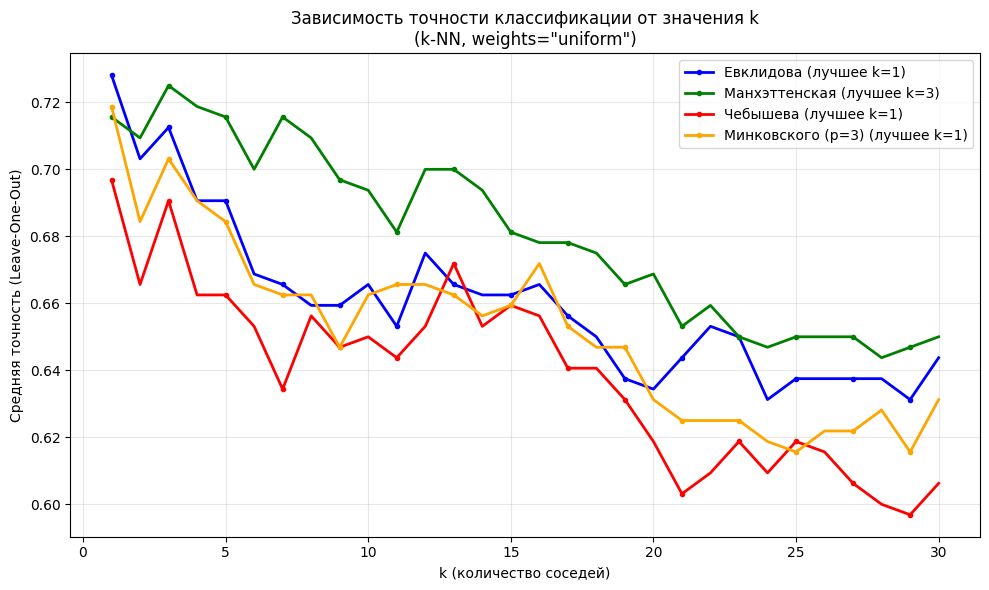


--- Оценка на тестовой выборке ---

k-NN (uniform) - Евклидова
--------------------------------------------------
  Accuracy:  0.6500 (65.00%)
  Recall:    0.6500 (65.00%)
  F1-score:  0.6497 (64.97%)

k-NN (uniform) - Манхэттенская
--------------------------------------------------
  Accuracy:  0.7375 (73.75%)
  Recall:    0.7375 (73.75%)
  F1-score:  0.7415 (74.15%)

k-NN (uniform) - Чебышева
--------------------------------------------------
  Accuracy:  0.6375 (63.75%)
  Recall:    0.6375 (63.75%)
  F1-score:  0.6333 (63.33%)

k-NN (uniform) - Минковского (p=3)
--------------------------------------------------
  Accuracy:  0.6500 (65.00%)
  Recall:    0.6500 (65.00%)
  F1-score:  0.6497 (64.97%)


In [4]:
print("\n" + "-" * 50)
print("1.1 k-NN с равномерными весами (weights='uniform')")
print("-" * 50)

knn_uniform_results = {}

print("\nПодбор оптимального k методом LOO")
for name, metric in metrics.items():
    best_k, best_acc, k_vals, acc_vals = find_best_k_loo(
        X_train, y_train, metric, max_k=30, weights='uniform'
    )
    knn_uniform_results[name] = {
        'best_k': best_k,
        'best_acc': best_acc,
        'k_vals': k_vals,
        'acc_vals': acc_vals
    }
    print(f"  {name}: оптимальное k = {best_k}, точность LOO = {best_acc:.4f} ({best_acc*100:.2f}%)")

# График зависимости точности от k для всех метрик
plt.figure(figsize=(10, 6))
for idx, (name, results) in enumerate(knn_uniform_results.items()):
    plt.plot(results['k_vals'], results['acc_vals'],
             label=f"{name} (лучшее k={results['best_k']})",
             color=colors[idx], linewidth=2, marker='o', markersize=3, markevery=2)
plt.xlabel('k (количество соседей)')
plt.ylabel('Средняя точность (Leave-One-Out)')
plt.title('Зависимость точности классификации от значения k\n(k-NN, weights="uniform")')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Оценка на тестовой выборке
print("\n--- Оценка на тестовой выборке ---")
for name, results in knn_uniform_results.items():
    best_k = results['best_k']
    metric = metrics[name]

    knn = KNeighborsClassifier(n_neighbors=best_k, metric=metric, weights='uniform')
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    print_classification_report(y_test, y_pred, f"k-NN (uniform) - {name}", le.classes_)

k-NN с весами по расстоянию (weights='distance')


--------------------------------------------------
1.2 k-NN с весами по расстоянию (weights='distance')
--------------------------------------------------

--- Подбор оптимального k методом LOO ---
  Евклидова: оптимальное k = 3, точность LOO = 0.7344 (73.44%)
  Манхэттенская: оптимальное k = 8, точность LOO = 0.7500 (75.00%)
  Чебышева: оптимальное k = 3, точность LOO = 0.7000 (70.00%)
  Минковского (p=3): оптимальное k = 3, точность LOO = 0.7219 (72.19%)


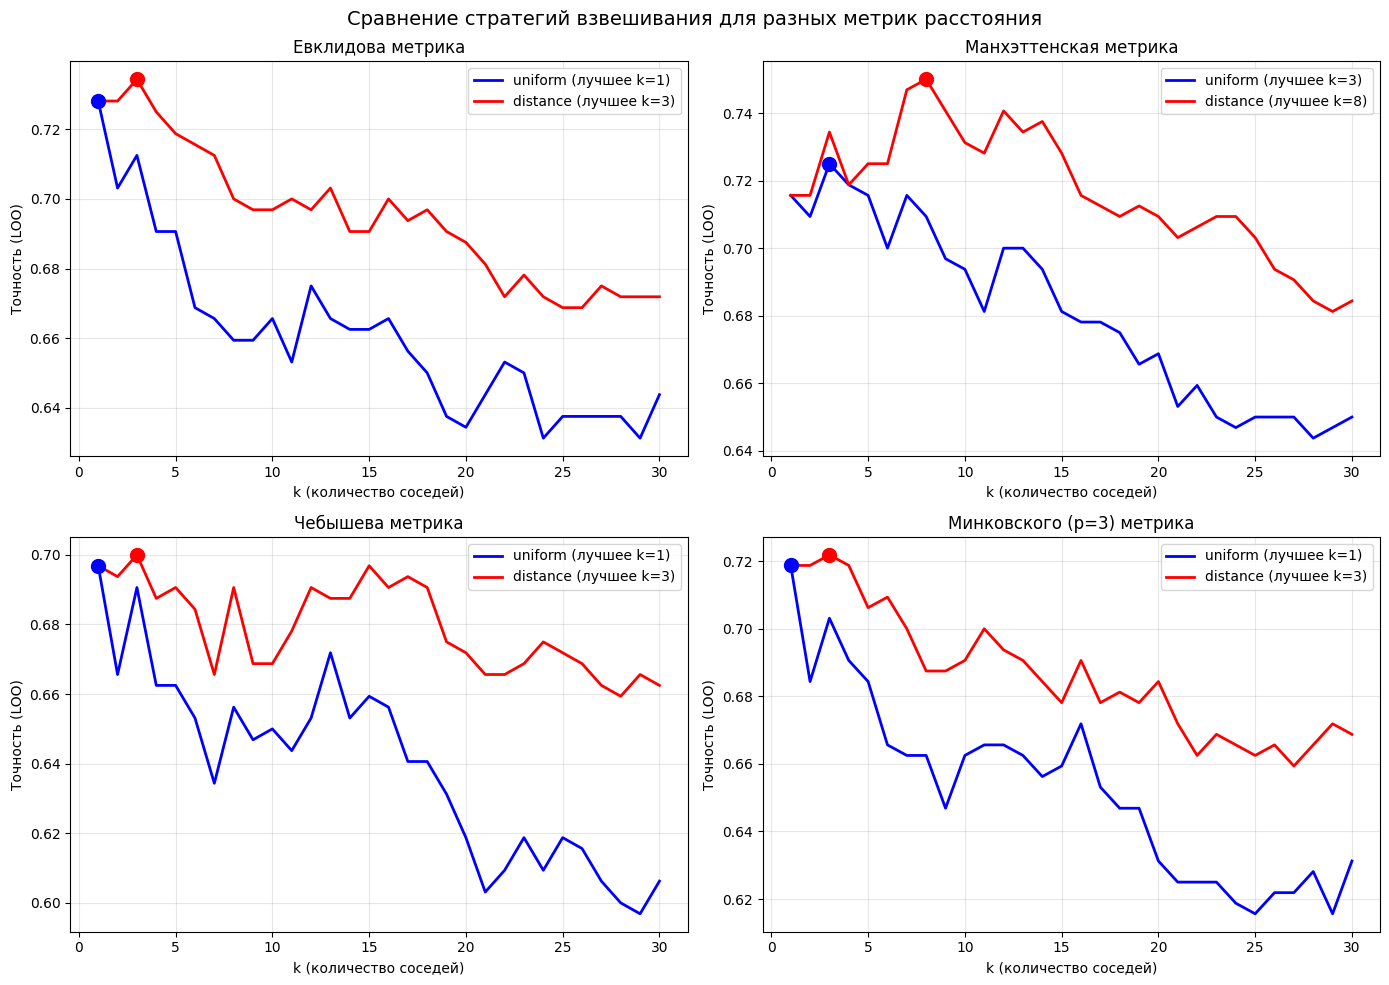


--- Оценка на тестовой выборке (weights='distance') ---

k-NN (distance) - Евклидова
--------------------------------------------------
  Accuracy:  0.7000 (70.00%)
  Recall:    0.7000 (70.00%)
  F1-score:  0.7014 (70.14%)

k-NN (distance) - Манхэттенская
--------------------------------------------------
  Accuracy:  0.7125 (71.25%)
  Recall:    0.7125 (71.25%)
  F1-score:  0.7088 (70.88%)

k-NN (distance) - Чебышева
--------------------------------------------------
  Accuracy:  0.6750 (67.50%)
  Recall:    0.6750 (67.50%)
  F1-score:  0.6738 (67.38%)

k-NN (distance) - Минковского (p=3)
--------------------------------------------------
  Accuracy:  0.7000 (70.00%)
  Recall:    0.7000 (70.00%)
  F1-score:  0.7014 (70.14%)


In [5]:
print("\n" + "-" * 50)
print("1.2 k-NN с весами по расстоянию (weights='distance')")
print("-" * 50)

knn_distance_results = {}

print("\n--- Подбор оптимального k методом LOO ---")
for name, metric in metrics.items():
    best_k, best_acc, k_vals, acc_vals = find_best_k_loo(
        X_train, y_train, metric, max_k=30, weights='distance'
    )
    knn_distance_results[name] = {
        'best_k': best_k,
        'best_acc': best_acc,
        'k_vals': k_vals,
        'acc_vals': acc_vals
    }
    print(f"  {name}: оптимальное k = {best_k}, точность LOO = {best_acc:.4f} ({best_acc*100:.2f}%)")

# Сравнительный график для каждой метрики
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (name, metric) in enumerate(metrics.items()):
    uniform_acc = knn_uniform_results[name]['acc_vals']
    distance_acc = knn_distance_results[name]['acc_vals']
    k_vals = range(1, len(uniform_acc) + 1)

    best_k_uniform = knn_uniform_results[name]['best_k']
    best_k_distance = knn_distance_results[name]['best_k']
    best_acc_uniform = knn_uniform_results[name]['best_acc']
    best_acc_distance = knn_distance_results[name]['best_acc']

    axes[idx].plot(k_vals, uniform_acc, 'b-', label=f'uniform (лучшее k={best_k_uniform})', linewidth=2)
    axes[idx].plot(k_vals, distance_acc, 'r-', label=f'distance (лучшее k={best_k_distance})', linewidth=2)
    axes[idx].scatter(best_k_uniform, best_acc_uniform, color='blue', s=100, zorder=5)
    axes[idx].scatter(best_k_distance, best_acc_distance, color='red', s=100, zorder=5)

    axes[idx].set_xlabel('k (количество соседей)')
    axes[idx].set_ylabel('Точность (LOO)')
    axes[idx].set_title(f'{name} метрика')
    axes[idx].legend(loc='best')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Сравнение стратегий взвешивания для разных метрик расстояния', fontsize=14)
plt.tight_layout()
plt.show()

# Оценка на тестовой выборке
print("\n--- Оценка на тестовой выборке (weights='distance') ---")
for name, results in knn_distance_results.items():
    best_k = results['best_k']
    metric = metrics[name]

    knn = KNeighborsClassifier(n_neighbors=best_k, metric=metric, weights='distance')
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    print_classification_report(y_test, y_pred, f"k-NN (distance) - {name}", le.classes_)

 Часть 2

Реализация метода окна Парзена с фиксированной шириной окна

In [6]:
def rectangular_kernel(distance, h):
    return 1.0 if distance <= h else 0.0

def gaussian_kernel(distance, h):
    return np.exp(-0.5 * (distance / h) ** 2)

class ParzenWindowClassifier:
    def __init__(self, metric='euclidean', kernel='gaussian', h=1.0, p=3):
        self.metric = metric
        self.kernel = kernel
        self.h = h
        self.p = p
        self.X_train = None
        self.y_train = None

    def _get_distance(self, x1, x2):
        if self.metric == 'euclidean':
            return np.sqrt(np.sum((x1 - x2) ** 2))
        elif self.metric == 'manhattan':
            return np.sum(np.abs(x1 - x2))
        elif self.metric == 'chebyshev':
            return np.max(np.abs(x1 - x2))
        elif self.metric == 'minkowski':
            return np.sum(np.abs(x1 - x2) ** self.p) ** (1/self.p)
        else:
            raise ValueError(f"Unknown metric: {self.metric}")

    def _get_kernel_value(self, distance):
        if self.kernel == 'rectangular':
            return rectangular_kernel(distance, self.h)
        elif self.kernel == 'gaussian':
            return gaussian_kernel(distance, self.h)
        else:
            raise ValueError(f"Unknown kernel: {self.kernel}")

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict_single(self, x):
        n_classes = len(np.unique(self.y_train))
        class_scores = np.zeros(n_classes)

        for i, x_train in enumerate(self.X_train):
            dist = self._get_distance(x, x_train)
            kernel_val = self._get_kernel_value(dist)
            class_scores[self.y_train[i]] += kernel_val

        if np.sum(class_scores) == 0:
            unique, counts = np.unique(self.y_train, return_counts=True)
            return unique[np.argmax(counts)]

        return np.argmax(class_scores)

    def predict(self, X):
        return np.array([self.predict_single(x) for x in X])


def select_best_h_loo(X, y, metric, kernel, h_values, p=3):
    """Подбор оптимальной ширины окна h методом Leave-One-Out"""
    loo = LeaveOneOut()
    accuracies = []

    for h in h_values:
        parzen = ParzenWindowClassifier(metric=metric, kernel=kernel, h=h, p=p)
        correct = 0
        total = 0

        for train_idx, test_idx in loo.split(X):
            X_train_loo, X_test_loo = X[train_idx], X[test_idx]
            y_train_loo, y_test_loo = y[train_idx], y[test_idx]

            parzen.fit(X_train_loo, y_train_loo)
            y_pred = parzen.predict_single(X_test_loo[0])

            if y_pred == y_test_loo:
                correct += 1
            total += 1

        accuracies.append(correct / total)

    best_idx = np.argmax(accuracies)
    best_h = h_values[best_idx]
    best_acc = accuracies[best_idx]

    return best_h, best_acc, h_values, accuracies


Метод Парзена с фиксированной шириной окна


--- Подбор оптимальной ширины окна h методом LOO ---

Ядро: RECTANGULAR
  Евклидова: оптимальное h = 0.607, точность LOO = 0.6219 (62.19%)
  Манхэттенская: оптимальное h = 0.945, точность LOO = 0.6312 (63.12%)
  Чебышева: оптимальное h = 0.269, точность LOO = 0.5687 (56.88%)
  Минковского (p=3): оптимальное h = 0.438, точность LOO = 0.6125 (61.25%)

Ядро: GAUSSIAN
  Евклидова: оптимальное h = 0.100, точность LOO = 0.7375 (73.75%)
  Манхэттенская: оптимальное h = 0.438, точность LOO = 0.7156 (71.56%)
  Чебышева: оптимальное h = 0.100, точность LOO = 0.7094 (70.94%)
  Минковского (p=3): оптимальное h = 0.100, точность LOO = 0.7188 (71.88%)


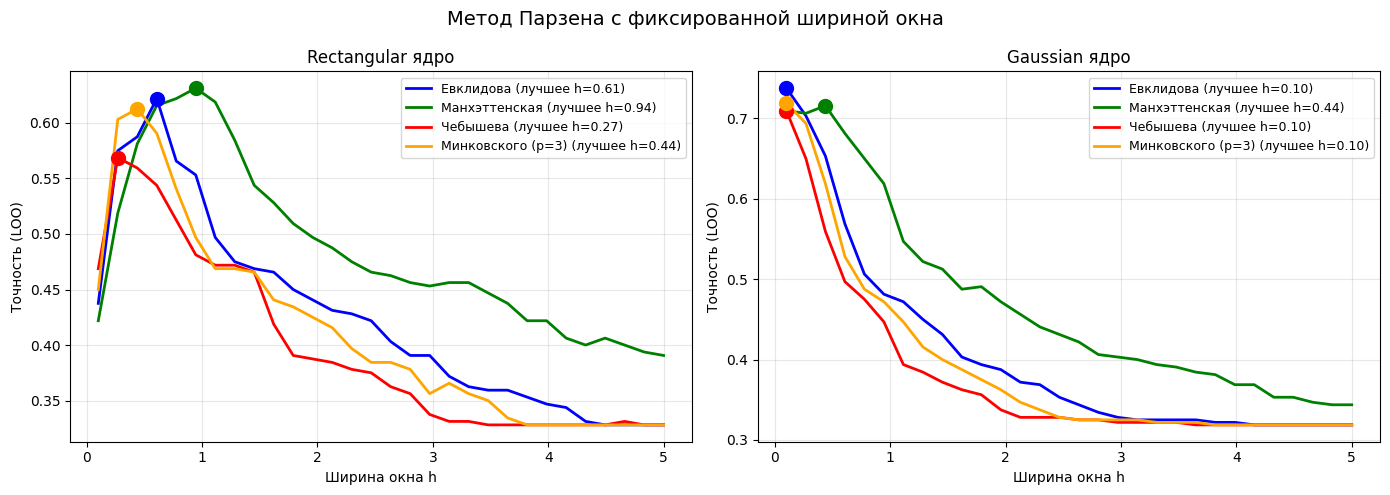


--- Оценка на тестовой выборке (фиксированная ширина окна) ---

Ядро: RECTANGULAR

Парзен (фикс, rectangular) - Евклидова
--------------------------------------------------
  Accuracy:  0.5750 (57.50%)
  Recall:    0.5750 (57.50%)
  F1-score:  0.5668 (56.68%)

Парзен (фикс, rectangular) - Манхэттенская
--------------------------------------------------
  Accuracy:  0.6000 (60.00%)
  Recall:    0.6000 (60.00%)
  F1-score:  0.5905 (59.05%)

Парзен (фикс, rectangular) - Чебышева
--------------------------------------------------
  Accuracy:  0.5125 (51.25%)
  Recall:    0.5125 (51.25%)
  F1-score:  0.5071 (50.71%)

Парзен (фикс, rectangular) - Минковского (p=3)
--------------------------------------------------
  Accuracy:  0.5750 (57.50%)
  Recall:    0.5750 (57.50%)
  F1-score:  0.5680 (56.80%)

Ядро: GAUSSIAN

Парзен (фикс, gaussian) - Евклидова
--------------------------------------------------
  Accuracy:  0.6875 (68.75%)
  Recall:    0.6875 (68.75%)
  F1-score:  0.6832 (68.32%)

Па

In [7]:
kernels = ['rectangular', 'gaussian']
h_values = np.linspace(0.1, 5.0, 30)
parzen_fixed_results = {}

print("\n--- Подбор оптимальной ширины окна h методом LOO ---")
for kernel in kernels:
    print(f"\nЯдро: {kernel.upper()}")
    for name, metric in metrics.items():
        best_h, best_acc, h_vals, acc_vals = select_best_h_loo(
            X_train, y_train, metric, kernel, h_values, p=3
        )
        parzen_fixed_results[f"{name}_{kernel}"] = {
            'metric': name,
            'kernel': kernel,
            'best_h': best_h,
            'best_acc': best_acc,
            'h_vals': h_vals,
            'acc_vals': acc_vals
        }
        print(f"  {name}: оптимальное h = {best_h:.3f}, точность LOO = {best_acc:.4f} ({best_acc*100:.2f}%)")

# Графики для фиксированной ширины окна
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, kernel in enumerate(kernels):
    for name, metric in enumerate(metrics.keys()):
        key = f"{metric}_{kernel}"
        if key in parzen_fixed_results:
            res = parzen_fixed_results[key]
            axes[idx].plot(res['h_vals'], res['acc_vals'],
                          label=f"{metric} (лучшее h={res['best_h']:.2f})",
                          color=colors[name], linewidth=2)
            axes[idx].scatter(res['best_h'], res['best_acc'], color=colors[name], s=100, zorder=5)

    axes[idx].set_xlabel('Ширина окна h')
    axes[idx].set_ylabel('Точность (LOO)')
    axes[idx].set_title(f'{kernel.capitalize()} ядро')
    axes[idx].legend(loc='best', fontsize=9)
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Метод Парзена с фиксированной шириной окна', fontsize=14)
plt.tight_layout()
plt.show()

# Оценка на тестовой выборке
print("\n--- Оценка на тестовой выборке (фиксированная ширина окна) ---")
for kernel in kernels:
    print(f"\nЯдро: {kernel.upper()}")
    for name, metric in metrics.items():
        key = f"{name}_{kernel}"
        if key in parzen_fixed_results:
            best_h = parzen_fixed_results[key]['best_h']

            parzen = ParzenWindowClassifier(metric=metric, kernel=kernel, h=best_h, p=3)
            parzen.fit(X_train, y_train)
            y_pred = parzen.predict(X_test)

            print_classification_report(y_test, y_pred, f"Парзен (фикс, {kernel}) - {name}", le.classes_)

Метод окна Парзена с переменной шириной

In [8]:

class ParzenWindowVariableClassifier:
    def __init__(self, metric='euclidean', kernel='gaussian', k=5, p=3):
        self.metric = metric
        self.kernel = kernel
        self.k = k
        self.p = p
        self.X_train = None
        self.y_train = None

    def _get_distance(self, x1, x2):
        if self.metric == 'euclidean':
            return np.sqrt(np.sum((x1 - x2) ** 2))
        elif self.metric == 'manhattan':
            return np.sum(np.abs(x1 - x2))
        elif self.metric == 'chebyshev':
            return np.max(np.abs(x1 - x2))
        elif self.metric == 'minkowski':
            return np.sum(np.abs(x1 - x2) ** self.p) ** (1/self.p)
        else:
            raise ValueError(f"Unknown metric: {self.metric}")

    def _get_kernel_value(self, distance, h):
        if self.kernel == 'rectangular':
            return 1.0 if distance <= h else 0.0
        elif self.kernel == 'gaussian':
            return np.exp(-0.5 * (distance / h) ** 2)
        else:
            raise ValueError(f"Unknown kernel: {self.kernel}")

    def _get_adaptive_h(self, x):
        distances = []
        for x_train in self.X_train:
            dist = self._get_distance(x, x_train)
            distances.append(dist)
        distances.sort()
        if len(distances) >= self.k:
            return distances[self.k - 1]
        else:
            return distances[-1] if distances else 1.0

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict_single(self, x):
        n_classes = len(np.unique(self.y_train))
        class_scores = np.zeros(n_classes)

        h_adaptive = self._get_adaptive_h(x)
        if h_adaptive == 0:
            h_adaptive = 1e-6

        for i, x_train in enumerate(self.X_train):
            dist = self._get_distance(x, x_train)
            kernel_val = self._get_kernel_value(dist, h_adaptive)
            class_scores[self.y_train[i]] += kernel_val

        if np.sum(class_scores) == 0:
            unique, counts = np.unique(self.y_train, return_counts=True)
            return unique[np.argmax(counts)]

        return np.argmax(class_scores)

    def predict(self, X):
        return np.array([self.predict_single(x) for x in X])


def select_best_k_parzen_variable(X, y, metric, kernel, k_values, p=3):
    """Подбор оптимального k для переменной ширины окна"""
    loo = LeaveOneOut()
    accuracies = []

    for k in k_values:
        parzen = ParzenWindowVariableClassifier(metric=metric, kernel=kernel, k=k, p=p)
        correct = 0
        total = 0

        for train_idx, test_idx in loo.split(X):
            X_train_loo, X_test_loo = X[train_idx], X[test_idx]
            y_train_loo, y_test_loo = y[train_idx], y[test_idx]

            parzen.fit(X_train_loo, y_train_loo)
            y_pred = parzen.predict_single(X_test_loo[0])

            if y_pred == y_test_loo:
                correct += 1
            total += 1

        accuracies.append(correct / total)

    best_idx = np.argmax(accuracies)
    best_k = k_values[best_idx]
    best_acc = accuracies[best_idx]

    return best_k, best_acc, k_values, accuracies

Метод Парзена с переменной шириной окна


--- Подбор оптимального k методом LOO ---

Ядро: RECTANGULAR
  Евклидова: оптимальное k = 1, точность LOO = 0.7281 (72.81%)
  Манхэттенская: оптимальное k = 3, точность LOO = 0.7250 (72.50%)
  Чебышева: оптимальное k = 1, точность LOO = 0.7000 (70.00%)
  Минковского (p=3): оптимальное k = 1, точность LOO = 0.7188 (71.88%)

Ядро: GAUSSIAN
  Евклидова: оптимальное k = 1, точность LOO = 0.7406 (74.06%)
  Манхэттенская: оптимальное k = 1, точность LOO = 0.7406 (74.06%)
  Чебышева: оптимальное k = 1, точность LOO = 0.7094 (70.94%)
  Минковского (p=3): оптимальное k = 1, точность LOO = 0.7312 (73.12%)


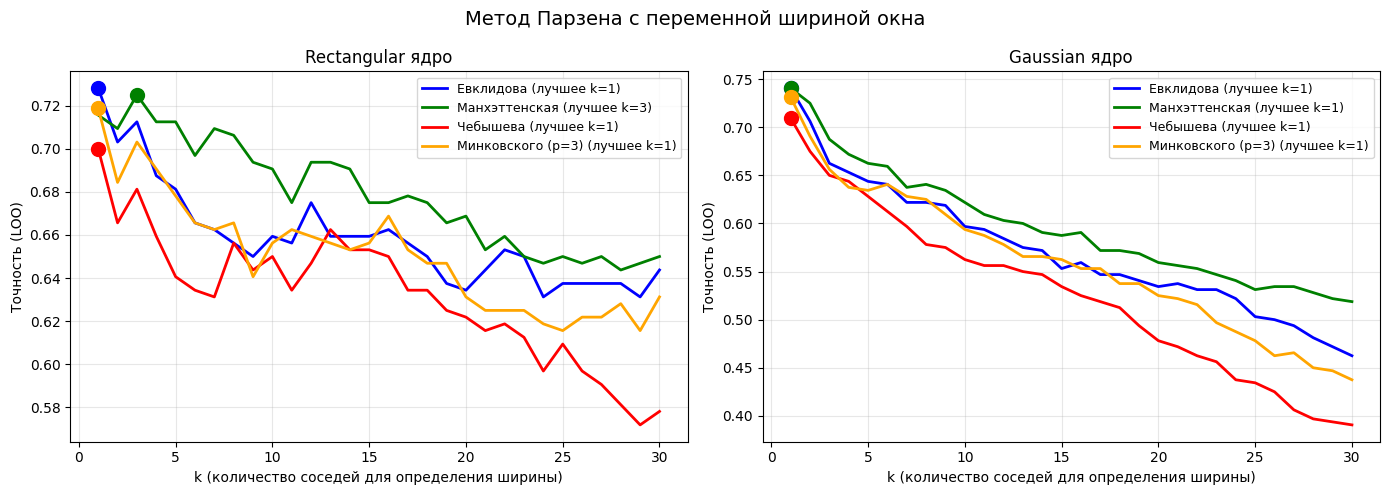


--- Оценка на тестовой выборке (переменная ширина окна) ---

Ядро: RECTANGULAR

Парзен (перем, rectangular) - Евклидова
--------------------------------------------------
  Accuracy:  0.6500 (65.00%)
  Recall:    0.6500 (65.00%)
  F1-score:  0.6497 (64.97%)

Парзен (перем, rectangular) - Манхэттенская
--------------------------------------------------
  Accuracy:  0.7375 (73.75%)
  Recall:    0.7375 (73.75%)
  F1-score:  0.7415 (74.15%)

Парзен (перем, rectangular) - Чебышева
--------------------------------------------------
  Accuracy:  0.6500 (65.00%)
  Recall:    0.6500 (65.00%)
  F1-score:  0.6471 (64.71%)

Парзен (перем, rectangular) - Минковского (p=3)
--------------------------------------------------
  Accuracy:  0.6750 (67.50%)
  Recall:    0.6750 (67.50%)
  F1-score:  0.6712 (67.12%)

Ядро: GAUSSIAN

Парзен (перем, gaussian) - Евклидова
--------------------------------------------------
  Accuracy:  0.7250 (72.50%)
  Recall:    0.7250 (72.50%)
  F1-score:  0.7218 (72.18%)



In [9]:
k_values_parzen = range(1, 31)
parzen_variable_results = {}

print("\n--- Подбор оптимального k методом LOO ---")
for kernel in kernels:
    print(f"\nЯдро: {kernel.upper()}")
    for name, metric in metrics.items():
        best_k, best_acc, k_vals, acc_vals = select_best_k_parzen_variable(
            X_train, y_train, metric, kernel, k_values_parzen, p=3
        )
        parzen_variable_results[f"{name}_{kernel}"] = {
            'metric': name,
            'kernel': kernel,
            'best_k': best_k,
            'best_acc': best_acc,
            'k_vals': k_vals,
            'acc_vals': acc_vals
        }
        print(f"  {name}: оптимальное k = {best_k}, точность LOO = {best_acc:.4f} ({best_acc*100:.2f}%)")

# Графики для переменной ширины окна
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, kernel in enumerate(kernels):
    for name, metric in enumerate(metrics.keys()):
        key = f"{metric}_{kernel}"
        if key in parzen_variable_results:
            res = parzen_variable_results[key]
            axes[idx].plot(res['k_vals'], res['acc_vals'],
                          label=f"{metric} (лучшее k={res['best_k']})",
                          color=colors[name], linewidth=2)
            axes[idx].scatter(res['best_k'], res['best_acc'], color=colors[name], s=100, zorder=5)

    axes[idx].set_xlabel('k (количество соседей для определения ширины)')
    axes[idx].set_ylabel('Точность (LOO)')
    axes[idx].set_title(f'{kernel.capitalize()} ядро')
    axes[idx].legend(loc='best', fontsize=9)
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Метод Парзена с переменной шириной окна', fontsize=14)
plt.tight_layout()
plt.show()

# Оценка на тестовой выборке
print("\n--- Оценка на тестовой выборке (переменная ширина окна) ---")
for kernel in kernels:
    print(f"\nЯдро: {kernel.upper()}")
    for name, metric in metrics.items():
        key = f"{name}_{kernel}"
        if key in parzen_variable_results:
            best_k = parzen_variable_results[key]['best_k']

            parzen = ParzenWindowVariableClassifier(metric=metric, kernel=kernel, k=best_k, p=3)
            parzen.fit(X_train, y_train)
            y_pred = parzen.predict(X_test)

            print_classification_report(y_test, y_pred, f"Парзен (перем, {kernel}) - {name}", le.classes_)

ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ

In [11]:
# Сбор всех результатов для сводной таблицы
summary_data = []

# k-NN uniform
for name, results in knn_uniform_results.items():
    summary_data.append({
        'Метод': 'k-NN (uniform)',
        'Метрика': name,
        'Параметр': f"k={results['best_k']}",
        'Accuracy (LOO)': results['best_acc']
    })

# k-NN distance
for name, results in knn_distance_results.items():
    summary_data.append({
        'Метод': 'k-NN (distance)',
        'Метрика': name,
        'Параметр': f"k={results['best_k']}",
        'Accuracy (LOO)': results['best_acc']
    })

# Парзен фикс
for key, results in parzen_fixed_results.items():
    summary_data.append({
        'Метод': f"Парзен (фикс, {results['kernel']})",
        'Метрика': results['metric'],
        'Параметр': f"h={results['best_h']:.3f}",
        'Accuracy (LOO)': results['best_acc']
    })

# Парзен перем
for key, results in parzen_variable_results.items():
    summary_data.append({
        'Метод': f"Парзен (перем, {results['kernel']})",
        'Метрика': results['metric'],
        'Параметр': f"k={results['best_k']}",
        'Accuracy (LOO)': results['best_acc']
    })

# Сортируем по убыванию точности
summary_sorted = sorted(summary_data, key=lambda x: x['Accuracy (LOO)'], reverse=True)

# Вывод таблицы
print(f"\n{'Метод':<35} {'Метрика':<20} {'Параметр':<12} {'Accuracy (LOO)':<15}")
print("-" * 85)
for r in summary_sorted:
    print(f"{r['Метод']:<35} {r['Метрика']:<20} {r['Параметр']:<12} {r['Accuracy (LOO)']:.4f}")

# Лучший результат
best_result = summary_sorted[0]
print("\n" + "-" * 30)
print("ЛУЧШИЙ РЕЗУЛЬТАТ")
print("-" * 30)
print(f"Метод: {best_result['Метод']}")
print(f"Метрика: {best_result['Метрика']}")
print(f"Параметр: {best_result['Параметр']}")
print(f"Точность LOO: {best_result['Accuracy (LOO)']:.4f} ({best_result['Accuracy (LOO)']*100:.2f}%)")


Метод                               Метрика              Параметр     Accuracy (LOO) 
-------------------------------------------------------------------------------------
k-NN (distance)                     Манхэттенская        k=8          0.7500
Парзен (перем, gaussian)            Евклидова            k=1          0.7406
Парзен (перем, gaussian)            Манхэттенская        k=1          0.7406
Парзен (фикс, gaussian)             Евклидова            h=0.100      0.7375
k-NN (distance)                     Евклидова            k=3          0.7344
Парзен (перем, gaussian)            Минковского (p=3)    k=1          0.7312
k-NN (uniform)                      Евклидова            k=1          0.7281
Парзен (перем, rectangular)         Евклидова            k=1          0.7281
k-NN (uniform)                      Манхэттенская        k=3          0.7250
Парзен (перем, rectangular)         Манхэттенская        k=3          0.7250
k-NN (distance)                     Минковского (p=3)    

Переменное окно Парзена систематически лучше (имеют неоднородную плотность ), фиксированное окно не может подстроиться под это, а переменное - может.

Gaussian ядро значительно эффективнее прямоугольного (более устойчив к выбору параметров - ошибка в h меньше влияет на результат)

Данные содержат выбросы (Манхэттенская менее чувствительна к выбросам)

Gaussian ядро предпочитает минимальную ширину окна (h=0.1) для большинства метрик, кроме Манхэттенской

Rectangular ядро требует большей ширины окна (0.27-0.95)